## Section 1: Setup & Data Loading

Download the dataset if needed, preprocess the source images and annotations, and refresh the cached `.pt` tensors. The dataset normalizes keypoints for the resized 96x96 images. We then build one shuffled training `DataLoader` and keep a fixed sample for a fair before/after comparison.

In [1]:
import os

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset

from dataset.data import download_udacity_dataset
from models.naimishnet import NaimishNet
from src.alignment_workflow import plot_prediction, transfer_backbone
from src.data_pipeline import FacialKeypointsDataset

# Download the dataset only if it is not already available.
download_udacity_dataset()

# Use the GPU when available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Preprocess the source images and keypoints for the model.
dataset = FacialKeypointsDataset(
    csv_file="data/training_frames_keypoints.csv",
    root_dir="data/training",
)
cache_loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=4)

# Collect and save the preprocessed tensors for reuse.
image_batches, keypoint_batches, mask_batches = [], [], []
for batch in cache_loader:
    image_batches.append(batch["image"])
    keypoint_batches.append(batch["keypoints"])
    mask_batches.append(batch["mask"])

all_images = torch.cat(image_batches)
all_keypoints = torch.cat(keypoint_batches)
all_masks = torch.cat(mask_batches)
torch.save(all_images, "data/all_images.pt")
torch.save(all_keypoints, "data/all_keypoints.pt")
torch.save(all_masks, "data/all_masks.pt")

# Load the cached tensors and create the shuffled training DataLoader.
all_images = torch.load("data/all_images.pt", map_location="cpu")
all_keypoints = torch.load("data/all_keypoints.pt", map_location="cpu")
all_masks = torch.load("data/all_masks.pt", map_location="cpu")
train_loader = DataLoader(
    TensorDataset(all_images, all_keypoints, all_masks),
    batch_size=32,
    shuffle=True,
)

# Keep one fixed image so both models are compared on the same input.
sample = dataset[0]
plot_batch = (
    sample["image"].unsqueeze(0),
    sample["keypoints"].unsqueeze(0),
    sample["mask"].unsqueeze(0),
)
os.makedirs("output", exist_ok=True)
print(f"Loaded {len(dataset)} images; batch shape: {next(iter(train_loader))[0].shape}")

Dataset already exists. Skipping download.
Loaded 3462 images; batch shape: torch.Size([32, 1, 96, 96])


/tmp/ipykernel_144940/2762511134.py:39: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  all_images = torch.load("data/all_images.pt", map_location="cpu")
/tmp/ipykernel_144940

## Section 2: Baseline NaimishNet Training

Train the baseline model from scratch for 10 epochs with masked mean-squared error and Adam. This model has no explicit spatial awareness. The loss is averaged over both X and Y coordinates for every valid landmark.

In [2]:
# Initialize the baseline model, loss function, and optimizer.
baseline = NaimishNet(use_bam_and_coord=False).to(device)
criterion = torch.nn.MSELoss(reduction="none")
optimizer = torch.optim.Adam(baseline.parameters(), lr=0.001)

# Train from scratch for 10 epochs.
for epoch in range(10):
    baseline.train()
    running_loss = 0.0

    for images, targets, masks in train_loader:
        images = images.to(device)
        targets = targets.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = baseline(images).reshape(-1, 90, 2)
        # Apply the mask and average across valid X and Y coordinates.
        coordinate_loss = criterion(outputs, targets) * masks.unsqueeze(-1)
        mean_loss = coordinate_loss.sum() / (masks.sum() * 2).clamp_min(1)

        mean_loss.backward()
        optimizer.step()
        running_loss += mean_loss.item()

    print(f"Epoch {epoch + 1}/10, loss: {running_loss / len(train_loader):.4f}")

# Save the trained baseline weights.
torch.save(baseline.state_dict(), "output/naimishnet_aligned.pth")
print("Saved output/naimishnet_aligned.pth")

Epoch 1/10, loss: 0.0372
Epoch 2/10, loss: 0.0050
Epoch 3/10, loss: 0.0047
Epoch 4/10, loss: 0.0044
Epoch 5/10, loss: 0.0041
Epoch 6/10, loss: 0.0039
Epoch 7/10, loss: 0.0036
Epoch 8/10, loss: 0.0034
Epoch 9/10, loss: 0.0034
Epoch 10/10, loss: 0.0029
Saved output/naimishnet_aligned.pth


## Section 3: Baseline Prediction (Visual Proof)

This is the “Before” picture. It plots predicted landmarks in red and valid ground-truth landmarks in green on the same fixed image, making any spatial degradation easy to see.

/tmp/ipykernel_144940/4079585785.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load("output/naimishnet_aligned.pth", map_location=device)


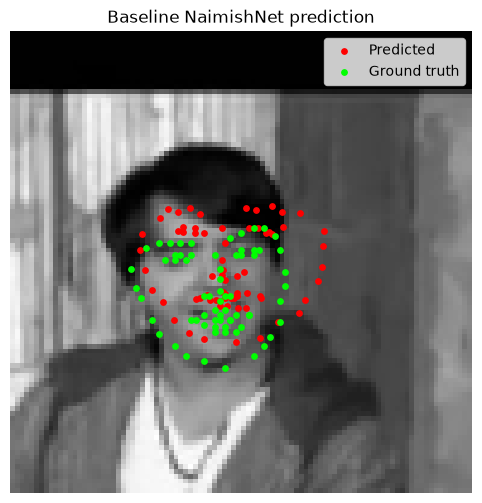

In [3]:
# Load the saved baseline weights and plot its prediction.
baseline_for_plot = NaimishNet(use_bam_and_coord=False).to(device)
# Initialize the lazy layer before loading the checkpoint.
with torch.no_grad():
    baseline_for_plot(plot_batch[0].to(device))
baseline_for_plot.load_state_dict(
    torch.load("output/naimishnet_aligned.pth", map_location=device)
)
plot_prediction(baseline_for_plot, plot_batch, device, "Baseline NaimishNet prediction")
plt.show()

## Section 4: Advanced Model Training (BAM + CoordConv)

Initialize the advanced model and its lazy layers, then transfer the compatible baseline convolutional weights. The first convolution is adapted for the added coordinate channels, while the regression head starts fresh. Train for 50 epochs with a lower learning rate of `0.0005`.

In [4]:
# Initialize the advanced model and its lazy layer.
advanced = NaimishNet(use_bam_and_coord=True).to(device)
advanced.eval()
with torch.no_grad():
    advanced(plot_batch[0].to(device))
# Copy compatible convolution weights from the baseline model.
transfer_backbone(baseline, advanced)

# Use the same masked loss, with a lower learning rate.
criterion = torch.nn.MSELoss(reduction="none")
optimizer = torch.optim.Adam(advanced.parameters(), lr=0.0005)
epochs = 50

# Train the advanced model for 50 epochs.
for epoch in range(epochs):
    advanced.train()
    running_loss = 0.0

    for images, targets, masks in train_loader:
        images = images.to(device)
        targets = targets.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = advanced(images).reshape(-1, 90, 2)
        # Average masked error across valid X and Y coordinates.
        coordinate_loss = criterion(outputs, targets) * masks.unsqueeze(-1)
        valid_coordinates = (masks.sum() * 2).clamp_min(1)
        loss = coordinate_loss.sum() / valid_coordinates

        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch {epoch + 1}/{epochs}, loss: {running_loss / len(train_loader):.4f}")

# Save the trained BAM + CoordConv weights.
torch.save(advanced.state_dict(), "output/naimishnet_bam_coord_aligned.pth")
print("Saved output/naimishnet_bam_coord_aligned.pth")

Epoch 1/50, loss: 0.0165
Epoch 2/50, loss: 0.0038
Epoch 3/50, loss: 0.0035
Epoch 4/50, loss: 0.0031
Epoch 5/50, loss: 0.0029
Epoch 6/50, loss: 0.0027
Epoch 7/50, loss: 0.0026
Epoch 8/50, loss: 0.0024
Epoch 9/50, loss: 0.0022
Epoch 10/50, loss: 0.0020
Epoch 11/50, loss: 0.0019
Epoch 12/50, loss: 0.0017
Epoch 13/50, loss: 0.0016
Epoch 14/50, loss: 0.0015
Epoch 15/50, loss: 0.0014
Epoch 16/50, loss: 0.0014
Epoch 17/50, loss: 0.0014
Epoch 18/50, loss: 0.0013
Epoch 19/50, loss: 0.0013
Epoch 20/50, loss: 0.0012
Epoch 21/50, loss: 0.0012
Epoch 22/50, loss: 0.0012
Epoch 23/50, loss: 0.0012
Epoch 24/50, loss: 0.0012
Epoch 25/50, loss: 0.0011
Epoch 26/50, loss: 0.0011
Epoch 27/50, loss: 0.0011
Epoch 28/50, loss: 0.0011
Epoch 29/50, loss: 0.0011
Epoch 30/50, loss: 0.0011
Epoch 31/50, loss: 0.0011
Epoch 32/50, loss: 0.0010
Epoch 33/50, loss: 0.0010
Epoch 34/50, loss: 0.0010
Epoch 35/50, loss: 0.0011
Epoch 36/50, loss: 0.0010
Epoch 37/50, loss: 0.0010
Epoch 38/50, loss: 0.0009
Epoch 39/50, loss: 0.

## Section 5: Advanced Prediction (The “After” Picture)

Visualize the final model with CoordConv and BAM on the same image as the baseline. Its keypoints should align more closely with facial features.

/tmp/ipykernel_144940/3912688331.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load("output/naimishnet_bam_coord_aligned.pth", map_location=device)


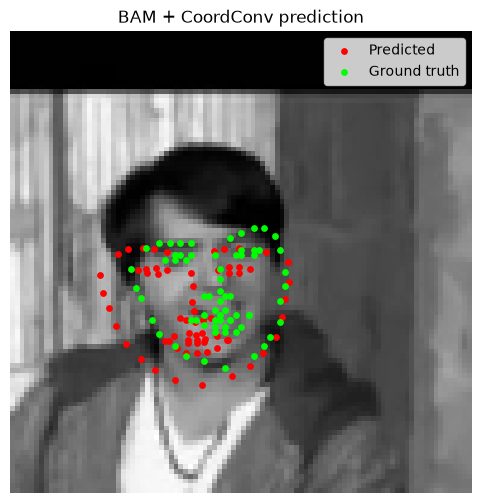

In [7]:
# Load the saved advanced weights and plot on the same image.
advanced_for_plot = NaimishNet(use_bam_and_coord=True).to(device)
advanced_for_plot.eval()
with torch.no_grad():
    advanced_for_plot(plot_batch[0].to(device))
advanced_for_plot.load_state_dict(
    torch.load("output/naimishnet_bam_coord_aligned.pth", map_location=device)
)
plot_prediction(advanced_for_plot, plot_batch, device, "BAM + CoordConv prediction")
plt.show()

NameError: name 'model_advanced' is not defined